In [1]:
# Import Libraries

import torch
import torch.nn as nn
import torch.optim as optim

torch.manual_seed(42)

In [2]:
# Create the XOR Dataset
X = torch.tensor([
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0]
])

y = torch.tensor([
    [0.0],
    [1.0],
    [1.0],
    [0.0]
])

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: torch.Size([4, 2])
Target shape: torch.Size([4, 1])


In [3]:
# Create Polynomial Feature and print it

x1 = X[:, 0:1]
x2 = X[:, 1:2]

interaction = x1 * x2

X_poly = torch.cat(
    [x1, x2, interaction],
    dim=1
)

print("Original inputs:")
print(X)

print("\nPolynomial features:")
print(X_poly)

print("\nNew shape:", X_poly.shape)

Original inputs:
tensor([[0., 0.],
        [0., 1.],
        [1., 0.],
        [1., 1.]])

Polynomial features:
tensor([[0., 0., 0.],
        [0., 1., 0.],
        [1., 0., 0.],
        [1., 1., 1.]])

New shape: torch.Size([4, 3])


In [4]:
# Build Polynomial Neuron

class PolynomialNeuron(nn.Module):

    def __init__(self):
        super().__init__()

        self.linear = nn.Linear(3, 1)

    def forward(self, x):

        x1 = x[:, 0:1]
        x2 = x[:, 1:2]

        interaction = x1 * x2

        polynomial_features = torch.cat(
            [x1, x2, interaction],
            dim=1
        )

        logits = self.linear(polynomial_features)

        return logits

In [5]:
# Instantiating the model

model = PolynomialNeuron()

print(model)

print("\nInitial weights:")
print(model.linear.weight.data)

print("\nInitial bias:")
print(model.linear.bias.data)

PolynomialNeuron(
  (linear): Linear(in_features=3, out_features=1, bias=True)
)

Initial weights:
tensor([[ 0.4414,  0.4792, -0.1353]])

Initial bias:
tensor([0.5304])


In [6]:
# Define Loss and Optimizer

criterion = nn.BCEWithLogitsLoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.1
)

In [7]:
# Train the polynomial neuron

num_epochs = 5000

loss_history = []

for epoch in range(num_epochs):

    # Clear previous gradients
    optimizer.zero_grad()

    # Forward pass
    logits = model(X)

    # Calculate loss
    loss = criterion(logits, y)

    # Backpropagation
    loss.backward()

    # Update weights and bias
    optimizer.step()

    # Store loss for later analysis
    loss_history.append(loss.item())

    if (epoch + 1) % 500 == 0:

        print(
            f"Epoch {epoch + 1:4d} | "
            f"Loss: {loss.item():.4f}"
        )

Epoch  500 | Loss: 0.3508
Epoch 1000 | Loss: 0.2312
Epoch 1500 | Loss: 0.1682
Epoch 2000 | Loss: 0.1307
Epoch 2500 | Loss: 0.1062
Epoch 3000 | Loss: 0.0892
Epoch 3500 | Loss: 0.0767
Epoch 4000 | Loss: 0.0671
Epoch 4500 | Loss: 0.0597
Epoch 5000 | Loss: 0.0536


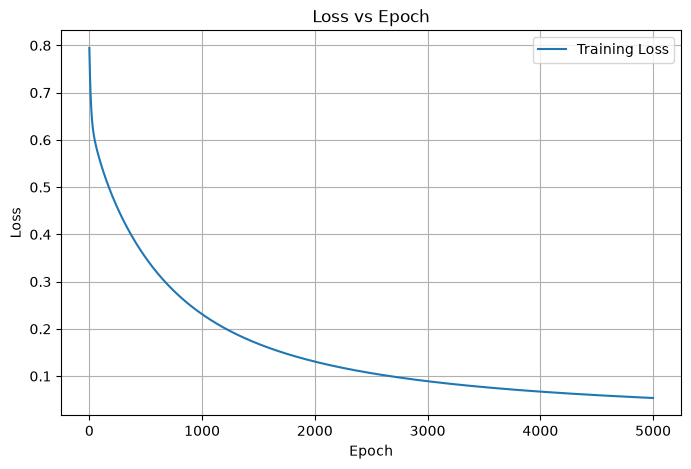

In [10]:
# Plot Loss Vs Epoch

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(loss_history, label="Training Loss")

plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

plt.show()

X-axis: Epoch number (0 to 4999)
Y-axis: Loss value
A downward trend indicates the model is learning.

##### Interpretation for an XOR model
The network is successfully learning the XOR pattern.
The optimizer is finding better weights over time.
The loss approaching 0 indicates predictions are becoming closer to the correct XOR outputs.

In short: the graph shows successful learning and convergence, with most learning occurring in the first 2000-3000 epochs and smaller refinements afterward.

In [9]:
# Evaluate the trained model

with torch.no_grad():

    logits = model(X)

    probabilities = torch.sigmoid(logits)

    predictions = (probabilities >= 0.5).float()


print("Final logits:")
print(logits)

print("\nFinal probabilities:")
print(probabilities)

print("\nPredictions:")
print(predictions)

print("\nCorrect targets:")
print(y)

print("\nLearned weights:")
print(model.linear.weight.data)

print("\nLearned bias:")
print(model.linear.bias.data)

accuracy = (predictions == y).float().mean()

print("\nAccuracy:", accuracy.item())

Final logits:
tensor([[-2.5080],
        [ 2.9453],
        [ 2.9453],
        [-3.3729]])

Final probabilities:
tensor([[0.0753],
        [0.9500],
        [0.9500],
        [0.0332]])

Predictions:
tensor([[0.],
        [1.],
        [1.],
        [0.]])

Correct targets:
tensor([[0.],
        [1.],
        [1.],
        [0.]])

Learned weights:
tensor([[  5.4533,   5.4533, -11.7714]])

Learned bias:
tensor([-2.5080])

Accuracy: 1.0



#### Interpretation: What Equation Did the Polynomial Neuron Learn?

The trained model learned the following parameters:

- w₁ = 5.4533
- w₂ = 5.4533
- w₃ = −11.7714
- b = −2.5080

Substituting these values into the degree-2 polynomial equation gives:

$$
z = 5.4533x_1 + 5.4533x_2 - 11.7714x_1x_2 - 2.5080
$$

This equation represents the trained polynomial neuron.

**Verification for the input (1,1):**

$$
z = 5.4533 + 5.4533 - 11.7714 - 2.5080
$$

$$
z \approx -3.3728
$$

Applying the sigmoid function:

$$
\sigma(-3.3728) \approx 0.0332
$$

Since the probability is below the classification threshold of 0.5, the model correctly predicts class 0.

**Interpretation:** The negative interaction coefficient reduces the output when both inputs are 1, allowing the neuron to capture the XOR relationship.

For comparison, the exact XOR polynomial for binary inputs is:

$$
XOR(x_1,x_2)=x_1+x_2-2x_1x_2
$$

Although the learned coefficients differ, both expressions capture the interaction required to represent XOR.

In [12]:
# Verifying BCE Loss and Accuracy together

with torch.no_grad():

    final_logits = model(X)

    final_loss = criterion(final_logits, y)

    final_probabilities = torch.sigmoid(final_logits)

    final_predictions = (
        final_probabilities >= 0.5
    ).float()

    final_accuracy = (
        final_predictions == y
    ).float().mean()


print(f"Final BCE Loss: {final_loss.item():.6f}")

print(f"Final Accuracy: {final_accuracy.item() * 100:.2f}%")

Final BCE Loss: 0.053626
Final Accuracy: 100.00%


BCE Loss Interpretation: The low final BCE loss of 0.053626 indicates that the model's predicted probabilities closely matched the correct XOR labels, demonstrating confident predictions.

Accuracy Interpretation: The model achieved 100% training accuracy, correctly classifying all four XOR input combinations (4/4).


### Final Experimental Results

| Metric | Result |
|---|---:|
| Training epochs | 5,000 |
| Final BCE loss | 0.053626 |
| Training accuracy | 100% |
| Correct predictions | 4/4 |

The degree-2 polynomial neuron successfully learned the XOR problem by incorporating the interaction term x1*x2. The final BCE loss of 0.053626 indicates that the predicted probabilities closely matched the correct labels, while the 100% training accuracy confirms that all four XOR examples were correctly classified. The training-loss graph shows a steady decrease in loss over the epochs, indicating that the model progressively learned the XOR pattern. Compared with the linear neuron (75% accuracy), this demonstrates how polynomial interactions increase the model’s representational capacity.
